In [1]:
from copy import deepcopy
from pathlib import Path
import random
import time
from tqdm import tqdm
from tqdm.contrib import tqdm as tqdm_contrib
import time
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import resnet18, ResNet18_Weights
import torchmetrics # This library is imported to calculate metrics. It was not in HW primary file

SEED = 42
DATA_ROOT = Path("data")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
print(f"Using device: {DEVICE}")

Using device: cuda


In [2]:
raw_trainval = OxfordIIITPet(root=DATA_ROOT, split="trainval", download=True, transform=None)
raw_test_full = OxfordIIITPet(root=DATA_ROOT, split="test", download=True, transform=None)

print(f"The Number of Classes = {len(raw_trainval.classes)}")
print(f"The Number of Training/Validation Instances = {len(raw_trainval)}")
print(f"The Number of Test Instances = {len(raw_test_full)}")

The Number of Classes = 37
The Number of Training/Validation Instances = 3680
The Number of Test Instances = 3669


In [3]:
print("Dataset's class names ...")
for i, name in enumerate(raw_trainval.classes):
    print(f"[{i}]: {name}")

Dataset's class names ...
[0]: Abyssinian
[1]: American Bulldog
[2]: American Pit Bull Terrier
[3]: Basset Hound
[4]: Beagle
[5]: Bengal
[6]: Birman
[7]: Bombay
[8]: Boxer
[9]: British Shorthair
[10]: Chihuahua
[11]: Egyptian Mau
[12]: English Cocker Spaniel
[13]: English Setter
[14]: German Shorthaired
[15]: Great Pyrenees
[16]: Havanese
[17]: Japanese Chin
[18]: Keeshond
[19]: Leonberger
[20]: Maine Coon
[21]: Miniature Pinscher
[22]: Newfoundland
[23]: Persian
[24]: Pomeranian
[25]: Pug
[26]: Ragdoll
[27]: Russian Blue
[28]: Saint Bernard
[29]: Samoyed
[30]: Scottish Terrier
[31]: Shiba Inu
[32]: Siamese
[33]: Sphynx
[34]: Staffordshire Bull Terrier
[35]: Wheaten Terrier
[36]: Yorkshire Terrier


In [4]:
def make_balanced_indices(targets, n_per_class, seed=SEED):
    '''Return a shuffled list of indices with exactly n_per_class examples
    per class in class_ids.'''
    chosens = {}
    for idx, target in enumerate(targets):
        if target not in chosens:
            chosens[target] = []
        
        if len(chosens[target]) < n_per_class:
            chosens[target].append(idx)
        # If already have n_per_class, skip this index

    indices = []
    for values in chosens.values():
        indices.extend(values)
    rng = random.Random(seed)
    rng.shuffle(indices)
    return indices


train_indices = make_balanced_indices(raw_trainval._labels, n_per_class=20, seed=SEED)
val_indices =   make_balanced_indices(raw_test_full._labels, n_per_class=8, seed=SEED)

class_names = raw_trainval.classes
NUM_CLASSES = len(class_names)
print("Classes:", NUM_CLASSES)
print("Train images:", len(train_indices), "| Val images:", len(val_indices))

Classes: 37
Train images: 740 | Val images: 296


In [5]:
class TransformSubset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        if idx >= len(self):
            raise IndexError(f"Index {idx} out of range for TransformSubset with length {len(self)}")
        # Get the image and label from the base dataset using the mapped index
        image, label = self.base_dataset[self.indices[idx]]
        
        # Apply transform if provided
        if self.transform:
            image = self.transform(image)
        
        return image, label
        


deterministic_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset = TransformSubset(raw_trainval, train_indices, deterministic_transform)
val_dataset = TransformSubset(raw_test_full, val_indices, deterministic_transform)

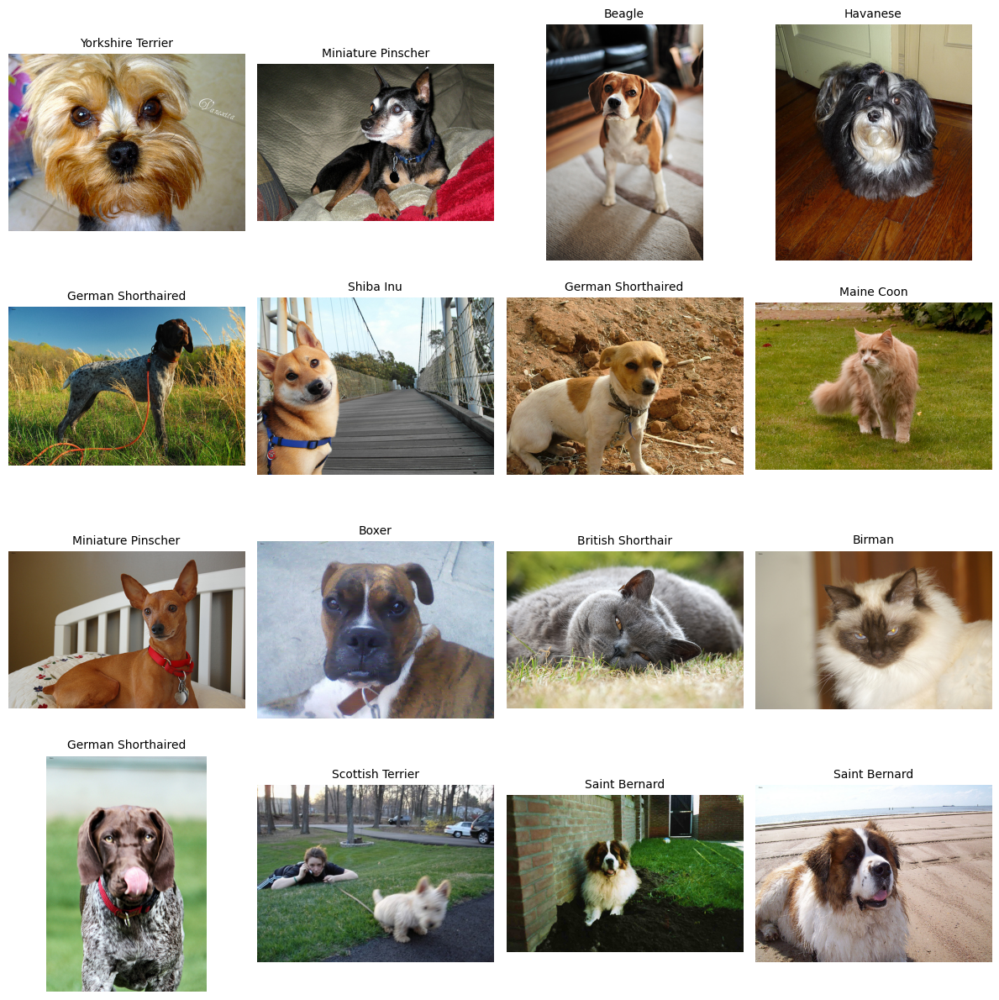

In [6]:
plain_dataset = TransformSubset(raw_trainval, train_indices, None)

def plot_image_grid(dataset, class_names, n_rows=4, n_cols=4):
    """
    Plot a grid of images with their labels from the dataset.
    """
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
    axes = axes.flatten()
    
    # Randomly select indices to display
    total_samples = len(dataset)
    if total_samples < n_rows * n_cols:
        selected_indices = list(range(total_samples))
        # Repeat if not enough samples
        selected_indices = selected_indices * (n_rows * n_cols // total_samples + 1)
        selected_indices = selected_indices[:n_rows * n_cols]
    else:
        selected_indices = np.random.choice(total_samples, n_rows * n_cols, replace=False)
    
    for idx, ax in enumerate(axes):
        if idx < len(selected_indices):
            # Get image and label
            image, label = dataset[selected_indices[idx]]
            
            # Display image
            if isinstance(image, Image.Image):
                ax.imshow(image)
            else:
                # If image is a tensor or numpy array
                ax.imshow(image)
            
            # Set title with label
            if class_names and label < len(class_names):
                title = f"{class_names[label]}"
            else:
                title = f"Label: {label}"
            
            ax.set_title(title, fontsize=10)
            ax.axis('off')
        else:
            ax.axis('off')
    
    plt.tight_layout()
    plt.show()

# Plot the grid
plot_image_grid(plain_dataset, raw_trainval.classes, n_rows=4, n_cols=4)

In [7]:
def make_loader(dataset, shuffle, batch_size=16, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0, generator=generator)

def evaluate_tm(model, data_loader, metric, device='cuda', desc=None):
    model.eval()
    metric.reset()
    
    if desc is None:
        desc = "Validating"
    
    # Create progress bar for evaluation
    eval_pbar = tqdm(data_loader, 
                     desc=desc,
                     leave=False,  # Remove after completion
                     unit="batch",
                     dynamic_ncols=True)
    
    with torch.no_grad():
        for batch_idx, (X_batch, y_batch) in enumerate(eval_pbar):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
            
            # Show current metric
            current_metric = metric.compute().item()
            eval_pbar.set_postfix({'metric': f'{current_metric:.2%}'})
    
    return metric.compute()

def set_bn_eval(model, layer_names=None):
    for name, module in model.named_modules():

        if not isinstance(module, nn.modules.batchnorm._BatchNorm):
            continue

        if layer_names is None:
            module.eval()
            continue

        if any(
            name == layer_name or name.startswith(layer_name + ".")
            for layer_name in layer_names
        ):
            module.eval()
    
def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name, frozen_bn_layers=None, patience=2, factor=0.5, epoch_callback=None, device='cuda'):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    best_valid_score = -1.

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()

        if frozen_bn_layers is not None:
            set_bn_eval(model, frozen_bn_layers)
        
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        
        # Create progress bar for this epoch
        train_pbar = tqdm(train_loader, 
                         desc=f"Epoch {epoch+1}/{n_epochs} [Train]",
                         leave=True,  # Keep the bar after completion
                         unit="batch",
                         dynamic_ncols=True)  # Adapt to terminal width
        
        for batch_idx, (X_batch, y_batch) in enumerate(train_pbar):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            
            # Update progress bar with current metrics (only once per batch)
            avg_loss = total_loss / (batch_idx + 1)
            train_pbar.set_postfix({
                'loss': f'{avg_loss:.4f}',
                'metric': f'{train_metric:.2%}'
            })
        
        # Calculate epoch averages
        avg_train_loss = total_loss / len(train_loader)
        avg_train_metric = train_metric
        
        history["train_losses"].append(avg_train_loss)
        history["train_metrics"].append(avg_train_metric)
        
        # Validation
        val_metric = evaluate_tm(model, valid_loader, metric, device=device)
        if val_metric > best_valid_score:
            best_valid_score = val_metric
            torch.save(model.state_dict(), f"models/{model_name}_model_weights.pth")
            
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        
        # Print epoch summary (clear line and print)
        print(f"\nEpoch {epoch+1}/{n_epochs} - "
              f"Train Loss: {avg_train_loss:.4f}, "
              f"Train Metric: {avg_train_metric:.2%}, "
              f"Valid Metric: {val_metric:.2%}, "
              f"LR: {optimizer.param_groups[0]['lr']:.2e}\n")
    
    return history

def freeze_layers(model, layer_names=None, unfreeze=True):
    """
    Freeze or unfreeze specific layers by name.
    
    Args:
        model: PyTorch model
        layer_names: List of layer names to freeze/unfreeze (if None, freeze all)
        unfreeze: If True, unfreeze specified layers; if False, freeze them
    """
    if layer_names is None:
        # Freeze/unfreeze all layers
        for param in model.parameters():
            param.requires_grad = unfreeze
        if unfreeze:
            model.train()
        else:
            model.eval()
        return
    
    for name, param in model.named_parameters():
        # Check if parameter belongs to specified layers
        is_target = any(layer_name in name for layer_name in layer_names)
        if is_target:
            param.requires_grad = unfreeze
        else:
            param.requires_grad = not unfreeze
    
    # Set model mode
    if unfreeze:
        model.train()
    else:
        model.eval()

def print_trainable_params(model):
    """
    Print which parameters are trainable.
    """
    trainable_count = 0
    total_count = 0
    
    print("Trainable parameters:")
    for name, param in model.named_parameters():
        total_count += param.numel()
        if param.requires_grad:
            trainable_count += param.numel()
            print(f"  ✓ {name}: {param.numel():,} params")
        else:
            print(f"  ✗ {name}: {param.numel():,} params (frozen)")
    
    print(f"\nTotal parameters: {total_count:,}")
    print(f"Trainable parameters: {trainable_count:,} ({100*trainable_count/total_count:.1f}%)")

In [8]:
set_seed()
weights = ResNet18_Weights.DEFAULT

feature_model = resnet18(weights=weights)
# freeze every parameter
freeze_layers(feature_model, layer_names=None, unfreeze=False)
print("Trainable modules after freezing all layers")
print_trainable_params(feature_model)
# TODO: replace feature_model.fc with a fresh nn.Linear(..., NUM_CLASSES)
num_features = feature_model.fc.in_features
feature_model.fc = nn.Linear(num_features, NUM_CLASSES)
feature_model = feature_model.to(DEVICE)
feature_model.trainable_modules = [feature_model.fc]
print("Trainable modules after adding new fc to the model")
print_trainable_params(feature_model)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)

optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)

print("Training ...\n\n")
n_epochs = 8
history = train(feature_model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="freeze_all_1", frozen_bn_layers=["layer1", "layer2", "layer3", "layer4"], patience=2, factor=0.5, epoch_callback=None, device=DEVICE)

Trainable modules after freezing all layers
Trainable parameters:
  ✗ conv1.weight: 9,408 params (frozen)
  ✗ bn1.weight: 64 params (frozen)
  ✗ bn1.bias: 64 params (frozen)
  ✗ layer1.0.conv1.weight: 36,864 params (frozen)
  ✗ layer1.0.bn1.weight: 64 params (frozen)
  ✗ layer1.0.bn1.bias: 64 params (frozen)
  ✗ layer1.0.conv2.weight: 36,864 params (frozen)
  ✗ layer1.0.bn2.weight: 64 params (frozen)
  ✗ layer1.0.bn2.bias: 64 params (frozen)
  ✗ layer1.1.conv1.weight: 36,864 params (frozen)
  ✗ layer1.1.bn1.weight: 64 params (frozen)
  ✗ layer1.1.bn1.bias: 64 params (frozen)
  ✗ layer1.1.conv2.weight: 36,864 params (frozen)
  ✗ layer1.1.bn2.weight: 64 params (frozen)
  ✗ layer1.1.bn2.bias: 64 params (frozen)
  ✗ layer2.0.conv1.weight: 73,728 params (frozen)
  ✗ layer2.0.bn1.weight: 128 params (frozen)
  ✗ layer2.0.bn1.bias: 128 params (frozen)
  ✗ layer2.0.conv2.weight: 147,456 params (frozen)
  ✗ layer2.0.bn2.weight: 128 params (frozen)
  ✗ layer2.0.bn2.bias: 128 params (frozen)
  ✗ l

Epoch 1/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:09<00:00,  4.81batch/s, loss=2.9560, metric=25.41%]
                                                                                                                                                           


Epoch 1/8 - Train Loss: 2.9560, Train Metric: 25.41%, Valid Metric: 49.32%, LR: 1.00e-03



Epoch 2/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.54batch/s, loss=1.2849, metric=78.65%]
                                                                                                                                                           


Epoch 2/8 - Train Loss: 1.2849, Train Metric: 78.65%, Valid Metric: 66.22%, LR: 1.00e-03



Epoch 3/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.64batch/s, loss=0.7647, metric=88.78%]
                                                                                                                                                           


Epoch 3/8 - Train Loss: 0.7647, Train Metric: 88.78%, Valid Metric: 70.61%, LR: 1.00e-03



Epoch 4/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.46batch/s, loss=0.5368, metric=93.11%]
                                                                                                                                                           


Epoch 4/8 - Train Loss: 0.5368, Train Metric: 93.11%, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 5/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.57batch/s, loss=0.4091, metric=95.95%]
                                                                                                                                                           


Epoch 5/8 - Train Loss: 0.4091, Train Metric: 95.95%, Valid Metric: 77.03%, LR: 1.00e-03



Epoch 6/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.21batch/s, loss=0.3208, metric=96.22%]
                                                                                                                                                           


Epoch 6/8 - Train Loss: 0.3208, Train Metric: 96.22%, Valid Metric: 75.00%, LR: 1.00e-03



Epoch 7/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.25batch/s, loss=0.2588, metric=97.16%]
                                                                                                                                                           


Epoch 7/8 - Train Loss: 0.2588, Train Metric: 97.16%, Valid Metric: 77.70%, LR: 1.00e-03



Epoch 8/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.62batch/s, loss=0.2168, metric=98.51%]
                                                                                                                                                           


Epoch 8/8 - Train Loss: 0.2168, Train Metric: 98.51%, Valid Metric: 77.36%, LR: 1.00e-03



In [9]:
def make_finetune_model(
    unfreeze_from,
    head_lr=1e-3,
    backbone_lr=1e-5
):
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)

    # Freeze everything
    for param in model.parameters():
        param.requires_grad = False

    # Replace classification head
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, NUM_CLASSES)

    param_groups = [
        {
            "params": model.fc.parameters(),
            "lr": head_lr
        }
    ]

    trainable_modules = [model.fc]

    if unfreeze_from in ("layer4", "all"):

        for param in model.layer4.parameters():
            param.requires_grad = True

        param_groups.append({
            "params": model.layer4.parameters(),
            "lr": backbone_lr
        })

        trainable_modules.append(model.layer4)

    if unfreeze_from == "all":

        remaining_modules = [
            model.conv1,
            model.bn1,
            model.layer1,
            model.layer2,
            model.layer3
        ]

        remaining_params = []

        for module in remaining_modules:

            for param in module.parameters():
                param.requires_grad = True
                remaining_params.append(param)

            trainable_modules.append(module)

        if remaining_params:
            param_groups.append({
                "params": remaining_params,
                "lr": backbone_lr
            })

    model = model.to(DEVICE)

    model.trainable_modules = trainable_modules

    optimizer = torch.optim.Adam(param_groups)

    return model, optimizer

In [10]:
probe_model, probe_optimizer = make_finetune_model("layer4")
# TODO: for each param_group in probe_optimizer.param_groups, print its lr and
#       the total number of parameters in that group (sum of p.numel() for p in group["params"])
total_trainable_params = 0
for param_group in probe_optimizer.param_groups:
    print(f"lr: {param_group['lr']}")
    total_trainable_params += sum(p.numel() for p in param_group['params'])
    print(f"total number of parameters in the group: {sum(p.numel() for p in param_group['params'])}")
assert sum(p.numel() for p in probe_model.parameters() if p.requires_grad) == total_trainable_params

lr: 0.001
total number of parameters in the group: 18981
lr: 1e-05
total number of parameters in the group: 8393728


In [12]:
def run_epoch_bn_frozen(model, loader, loss_fn, optimizer=None, frozen_bn_module=None):
    '''Same as run_epoch, but if frozen_bn_module is given, force every
    BatchNorm2d inside it back to eval() after the train()/eval() bookkeeping.'''
    is_training = optimizer is not None
    model.eval()
    if is_training:
        for module in model.trainable_modules:
            module.train()
        if frozen_bn_module is not None:
            # TODO: iterate frozen_bn_module.modules() and call .eval() on every
            #       instance of nn.BatchNorm2d you find, so their running stats
            #       stop updating even though the rest of the module is training.
            pass

    total_loss, total_correct, total_examples = 0.0, 0, 0
    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            loss = loss_fn(logits, labels)
            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += batch_size

    return {"loss": total_loss / total_examples, "accuracy": total_correct / total_examples}


set_seed()
# TODO: Run A -- normal fine-tuning, BatchNorm allowed to update its running stats.
model_a, optimizer_a = make_finetune_model("layer4")
# history_a = {"val_accuracy": []}
# for epoch in range(8):
#     run_epoch_bn_frozen(model_a, train_loader, loss_fn, optimizer=optimizer_a)
#     val_metrics = run_epoch_bn_frozen(model_a, val_loader, loss_fn)
#     history_a["val_accuracy"].append(val_metrics["accuracy"])

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)
    
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)
loss_fn = nn.CrossEntropyLoss()
print("Training ...\n\n")
n_epochs = 8
history_a = train(model_a, optimizer_a, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="unfreeze_4_no_bn_eval",frozen_bn_layers=None, patience=2, factor=0.5, epoch_callback=None, device=DEVICE)

Training ...




Epoch 1/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.22batch/s, loss=3.0813, metric=21.89%]
                                                                                                                                                           


Epoch 1/8 - Train Loss: 3.0813, Train Metric: 21.89%, Valid Metric: 46.62%, LR: 1.00e-03



Epoch 2/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.12batch/s, loss=1.4659, metric=74.59%]
                                                                                                                                                           


Epoch 2/8 - Train Loss: 1.4659, Train Metric: 74.59%, Valid Metric: 63.18%, LR: 1.00e-03



Epoch 3/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.8615, metric=86.76%]
                                                                                                                                                           


Epoch 3/8 - Train Loss: 0.8615, Train Metric: 86.76%, Valid Metric: 68.58%, LR: 1.00e-03



Epoch 4/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.17batch/s, loss=0.6246, metric=89.86%]
                                                                                                                                                           


Epoch 4/8 - Train Loss: 0.6246, Train Metric: 89.86%, Valid Metric: 70.61%, LR: 1.00e-03



Epoch 5/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.02batch/s, loss=0.4472, metric=93.92%]
                                                                                                                                                           


Epoch 5/8 - Train Loss: 0.4472, Train Metric: 93.92%, Valid Metric: 71.62%, LR: 1.00e-03



Epoch 6/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.10batch/s, loss=0.3295, metric=96.35%]
                                                                                                                                                           


Epoch 6/8 - Train Loss: 0.3295, Train Metric: 96.35%, Valid Metric: 71.28%, LR: 1.00e-03



Epoch 7/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.09batch/s, loss=0.2838, metric=97.03%]
                                                                                                                                                           


Epoch 7/8 - Train Loss: 0.2838, Train Metric: 97.03%, Valid Metric: 76.01%, LR: 1.00e-03



Epoch 8/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.12batch/s, loss=0.2305, metric=98.11%]
                                                                                                                                                           


Epoch 8/8 - Train Loss: 0.2305, Train Metric: 98.11%, Valid Metric: 73.99%, LR: 1.00e-03



In [13]:
def freeze_batchnorm_stats(model):
    """
    Freeze BatchNorm running statistics (mean and variance) by setting
    BatchNorm layers to eval mode while keeping other layers in train mode.
    """
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()
            # Optionally, you can also freeze the parameters
            for param in module.parameters():
                param.requires_grad = False

In [15]:
# TODO: Run B -- same setup, but pass frozen_bn_module=model_b.layer4 so its
#       BatchNorm running stats stay locked at ImageNet values.
set_seed()
model_b, optimizer_b = make_finetune_model("layer4")
freeze_batchnorm_stats(model_b.layer4)
train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)
loss_fn = nn.CrossEntropyLoss()

print("Training ...\n\n")
n_epochs = 8
history_b = train(model_b, optimizer_b, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="unfreeze_4_with_bn_eval", frozen_bn_layers=["layer1", "layer2", "layer3"], patience=2, factor=0.5, epoch_callback=None, device=DEVICE)

Training ...




Epoch 1/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=3.1150, metric=20.14%]
                                                                                                                                                           


Epoch 1/8 - Train Loss: 3.1150, Train Metric: 20.14%, Valid Metric: 45.95%, LR: 1.00e-03



Epoch 2/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.03batch/s, loss=1.4882, metric=74.86%]
                                                                                                                                                           


Epoch 2/8 - Train Loss: 1.4882, Train Metric: 74.86%, Valid Metric: 63.18%, LR: 1.00e-03



Epoch 3/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.07batch/s, loss=0.8521, metric=87.84%]
                                                                                                                                                           


Epoch 3/8 - Train Loss: 0.8521, Train Metric: 87.84%, Valid Metric: 70.27%, LR: 1.00e-03



Epoch 4/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.09batch/s, loss=0.6057, metric=91.62%]
                                                                                                                                                           


Epoch 4/8 - Train Loss: 0.6057, Train Metric: 91.62%, Valid Metric: 75.00%, LR: 1.00e-03



Epoch 5/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.05batch/s, loss=0.4298, metric=95.54%]
                                                                                                                                                           


Epoch 5/8 - Train Loss: 0.4298, Train Metric: 95.54%, Valid Metric: 73.99%, LR: 1.00e-03



Epoch 6/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.98batch/s, loss=0.3187, metric=96.35%]
                                                                                                                                                           


Epoch 6/8 - Train Loss: 0.3187, Train Metric: 96.35%, Valid Metric: 73.65%, LR: 1.00e-03



Epoch 7/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.04batch/s, loss=0.2649, metric=97.03%]
                                                                                                                                                           


Epoch 7/8 - Train Loss: 0.2649, Train Metric: 97.03%, Valid Metric: 76.35%, LR: 1.00e-03



Epoch 8/8 [Train]: 100%|████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.2177, metric=97.43%]
                                                                                                                                                           


Epoch 8/8 - Train Loss: 0.2177, Train Metric: 97.43%, Valid Metric: 76.35%, LR: 1.00e-03



In [16]:
histories = {}
for unfreeze_from in ["none", "layer4", "all"]:
    set_seed()
    train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
    train_loader = make_loader(train_dataset_aug, shuffle=True)
    valid_loader = make_loader(val_dataset, shuffle=False)
    model, optimizer = make_finetune_model(unfreeze_from)
    metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    print("*" * 20)
    print(f"Training {unfreeze_from} ...\n\n")
    print("*" * 20)
    n_epochs = 20
    
    if unfreeze_from == "none":
        frozen_bn_layers = ["layer1", "layer2", "layer3", "layer4"]
    elif frozen_bn_layers == "layer4":
        frozen_bn_layers = ["layer1", "layer2", "layer3"]
    else:
        frozen_bn_layers = None
        
    history = train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name=unfreeze_from, patience=2, factor=0.5, epoch_callback=None, device=DEVICE)
    histories[unfreeze_from] = history

********************
Training none ...


********************


Epoch 1/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=3.1653, metric=19.19%]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 3.1653, Train Metric: 19.19%, Valid Metric: 43.24%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=1.6798, metric=68.78%]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 1.6798, Train Metric: 68.78%, Valid Metric: 60.47%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.34batch/s, loss=1.0764, metric=82.57%]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 1.0764, Train Metric: 82.57%, Valid Metric: 65.88%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=0.8166, metric=86.89%]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 0.8166, Train Metric: 86.89%, Valid Metric: 67.57%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.43batch/s, loss=0.6303, metric=90.68%]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 0.6303, Train Metric: 90.68%, Valid Metric: 71.96%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.21batch/s, loss=0.4976, metric=93.24%]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 0.4976, Train Metric: 93.24%, Valid Metric: 70.27%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.45batch/s, loss=0.4367, metric=94.32%]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 0.4367, Train Metric: 94.32%, Valid Metric: 74.32%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=0.3782, metric=94.32%]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 0.3782, Train Metric: 94.32%, Valid Metric: 72.30%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.26batch/s, loss=0.3155, metric=96.76%]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 0.3155, Train Metric: 96.76%, Valid Metric: 72.30%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.32batch/s, loss=0.2992, metric=96.35%]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 0.2992, Train Metric: 96.35%, Valid Metric: 70.95%, LR: 5.00e-04



Epoch 11/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=0.2645, metric=97.03%]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 0.2645, Train Metric: 97.03%, Valid Metric: 73.31%, LR: 5.00e-04



Epoch 12/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.28batch/s, loss=0.2339, metric=98.92%]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 0.2339, Train Metric: 98.92%, Valid Metric: 73.99%, LR: 5.00e-04



Epoch 13/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.23batch/s, loss=0.2392, metric=98.11%]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 0.2392, Train Metric: 98.11%, Valid Metric: 72.30%, LR: 2.50e-04



Epoch 14/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=0.2077, metric=98.38%]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 0.2077, Train Metric: 98.38%, Valid Metric: 74.32%, LR: 2.50e-04



Epoch 15/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=0.2111, metric=98.11%]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 0.2111, Train Metric: 98.11%, Valid Metric: 73.99%, LR: 2.50e-04



Epoch 16/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.23batch/s, loss=0.1908, metric=98.11%]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 0.1908, Train Metric: 98.11%, Valid Metric: 73.65%, LR: 1.25e-04



Epoch 17/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.43batch/s, loss=0.1981, metric=98.78%]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 0.1981, Train Metric: 98.78%, Valid Metric: 75.34%, LR: 1.25e-04



Epoch 18/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.34batch/s, loss=0.1798, metric=99.46%]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 0.1798, Train Metric: 99.46%, Valid Metric: 73.65%, LR: 1.25e-04



Epoch 19/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.56batch/s, loss=0.1971, metric=98.51%]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 0.1971, Train Metric: 98.51%, Valid Metric: 73.65%, LR: 1.25e-04



Epoch 20/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.49batch/s, loss=0.1976, metric=98.78%]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 0.1976, Train Metric: 98.78%, Valid Metric: 72.30%, LR: 6.25e-05

********************
Training layer4 ...


********************


Epoch 1/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.29batch/s, loss=3.0813, metric=21.89%]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 3.0813, Train Metric: 21.89%, Valid Metric: 46.62%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.46batch/s, loss=1.4659, metric=74.59%]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 1.4659, Train Metric: 74.59%, Valid Metric: 63.18%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.8615, metric=86.76%]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 0.8615, Train Metric: 86.76%, Valid Metric: 68.58%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.6246, metric=89.86%]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 0.6246, Train Metric: 89.86%, Valid Metric: 70.61%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.99batch/s, loss=0.4472, metric=93.92%]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 0.4472, Train Metric: 93.92%, Valid Metric: 71.62%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.08batch/s, loss=0.3295, metric=96.35%]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 0.3295, Train Metric: 96.35%, Valid Metric: 71.28%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.05batch/s, loss=0.2838, metric=97.03%]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 0.2838, Train Metric: 97.03%, Valid Metric: 76.01%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.11batch/s, loss=0.2305, metric=98.11%]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 0.2305, Train Metric: 98.11%, Valid Metric: 73.99%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.1782, metric=98.78%]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 0.1782, Train Metric: 98.78%, Valid Metric: 74.32%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.99batch/s, loss=0.1621, metric=98.92%]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 0.1621, Train Metric: 98.92%, Valid Metric: 72.64%, LR: 5.00e-04



Epoch 11/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.06batch/s, loss=0.1344, metric=99.19%]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 0.1344, Train Metric: 99.19%, Valid Metric: 77.03%, LR: 5.00e-04



Epoch 12/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.04batch/s, loss=0.1148, metric=99.59%]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 0.1148, Train Metric: 99.59%, Valid Metric: 75.00%, LR: 5.00e-04



Epoch 13/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.08batch/s, loss=0.1187, metric=99.59%]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 0.1187, Train Metric: 99.59%, Valid Metric: 75.00%, LR: 5.00e-04



Epoch 14/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.18batch/s, loss=0.0965, metric=99.73%]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 0.0965, Train Metric: 99.73%, Valid Metric: 76.01%, LR: 2.50e-04



Epoch 15/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.08batch/s, loss=0.0977, metric=99.73%]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 0.0977, Train Metric: 99.73%, Valid Metric: 76.69%, LR: 2.50e-04



Epoch 16/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.09batch/s, loss=0.0843, metric=99.73%]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 0.0843, Train Metric: 99.73%, Valid Metric: 75.68%, LR: 2.50e-04



Epoch 17/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=0.0857, metric=99.86%]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 0.0857, Train Metric: 99.86%, Valid Metric: 77.03%, LR: 1.25e-04



Epoch 18/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=0.0750, metric=100.00%]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 0.0750, Train Metric: 100.00%, Valid Metric: 75.00%, LR: 1.25e-04



Epoch 19/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.02batch/s, loss=0.0850, metric=99.32%]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 0.0850, Train Metric: 99.32%, Valid Metric: 75.68%, LR: 1.25e-04



Epoch 20/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.96batch/s, loss=0.0898, metric=100.00%]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 0.0898, Train Metric: 100.00%, Valid Metric: 74.32%, LR: 6.25e-05

********************
Training all ...


********************


Epoch 1/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.78batch/s, loss=3.0724, metric=22.16%]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 3.0724, Train Metric: 22.16%, Valid Metric: 47.64%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.89batch/s, loss=1.4204, metric=76.08%]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 1.4204, Train Metric: 76.08%, Valid Metric: 63.85%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.95batch/s, loss=0.8030, metric=88.51%]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 0.8030, Train Metric: 88.51%, Valid Metric: 68.92%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=0.5674, metric=91.49%]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 0.5674, Train Metric: 91.49%, Valid Metric: 71.62%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.97batch/s, loss=0.3916, metric=95.27%]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 0.3916, Train Metric: 95.27%, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=0.2855, metric=97.30%]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 0.2855, Train Metric: 97.30%, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.03batch/s, loss=0.2454, metric=97.30%]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 0.2454, Train Metric: 97.30%, Valid Metric: 76.69%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.95batch/s, loss=0.1923, metric=98.24%]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 0.1923, Train Metric: 98.24%, Valid Metric: 75.68%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.91batch/s, loss=0.1446, metric=98.78%]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 0.1446, Train Metric: 98.78%, Valid Metric: 77.36%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.08batch/s, loss=0.1304, metric=99.32%]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 0.1304, Train Metric: 99.32%, Valid Metric: 73.99%, LR: 1.00e-03



Epoch 11/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.99batch/s, loss=0.1114, metric=99.59%]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 0.1114, Train Metric: 99.59%, Valid Metric: 79.39%, LR: 1.00e-03



Epoch 12/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.04batch/s, loss=0.0896, metric=99.73%]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 0.0896, Train Metric: 99.73%, Valid Metric: 77.03%, LR: 1.00e-03



Epoch 13/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  3.99batch/s, loss=0.0890, metric=99.32%]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 0.0890, Train Metric: 99.32%, Valid Metric: 77.03%, LR: 1.00e-03



Epoch 14/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.03batch/s, loss=0.0632, metric=99.86%]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 0.0632, Train Metric: 99.86%, Valid Metric: 76.69%, LR: 5.00e-04



Epoch 15/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.07batch/s, loss=0.0591, metric=99.86%]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 0.0591, Train Metric: 99.86%, Valid Metric: 79.05%, LR: 5.00e-04



Epoch 16/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.59batch/s, loss=0.0480, metric=100.00%]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 0.0480, Train Metric: 100.00%, Valid Metric: 77.36%, LR: 5.00e-04



Epoch 17/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.14batch/s, loss=0.0488, metric=100.00%]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 0.0488, Train Metric: 100.00%, Valid Metric: 77.70%, LR: 2.50e-04



Epoch 18/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=0.0405, metric=100.00%]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 0.0405, Train Metric: 100.00%, Valid Metric: 78.38%, LR: 2.50e-04



Epoch 19/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=0.0483, metric=99.86%]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 0.0483, Train Metric: 99.86%, Valid Metric: 78.04%, LR: 2.50e-04



Epoch 20/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.82batch/s, loss=0.0539, metric=100.00%]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 0.0539, Train Metric: 100.00%, Valid Metric: 77.70%, LR: 1.25e-04



In [20]:
# Plot all three strategies on the same plot
def plot_metric(histories, metric, y_label, is_tensor):
    plt.figure(figsize=(10, 6))
    epochs = range(1, n_epochs + 1)
    # ["none", "layer4", "all"
    if is_tensor:
        val_acc_strategy1 = [val.item() for val in histories['none'][metric]]
        val_acc_strategy2 = [val.item() for val in histories['layer4'][metric]]
        val_acc_strategy3 = [val.item() for val in histories['all'][metric]]
    else:
        val_acc_strategy1 = histories['none'][metric]
        val_acc_strategy2 = histories['layer4'][metric]
        val_acc_strategy3 = histories['all'][metric]
    
    plt.plot(epochs, val_acc_strategy1, 
             marker='o', linewidth=2, markersize=8, 
             label='Strategy 1: Freeze all, train FC', color='blue')

    plt.plot(epochs, val_acc_strategy2, 
             marker='s', linewidth=2, markersize=8, 
             label='Strategy 2: Freeze all, train FC + Layer4', color='green')

    plt.plot(epochs, val_acc_strategy3, 
             marker='^', linewidth=2, markersize=8, 
             label='Strategy 3: Fine-tune all layers', color='red')

    # Customize the plot
    plt.xlabel('Epochs', fontsize=12, fontweight='bold')
    plt.ylabel(y_label, fontsize=12, fontweight='bold')
    plt.title('Comparison of Fine-tuning Strategies on ResNet18', fontsize=14, fontweight='bold')
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.ylim([0.4, 1.0])  # Set y-axis limits
    plt.xticks(epochs)  # Show all epoch numbers
    plt.tight_layout()
    plt.show()

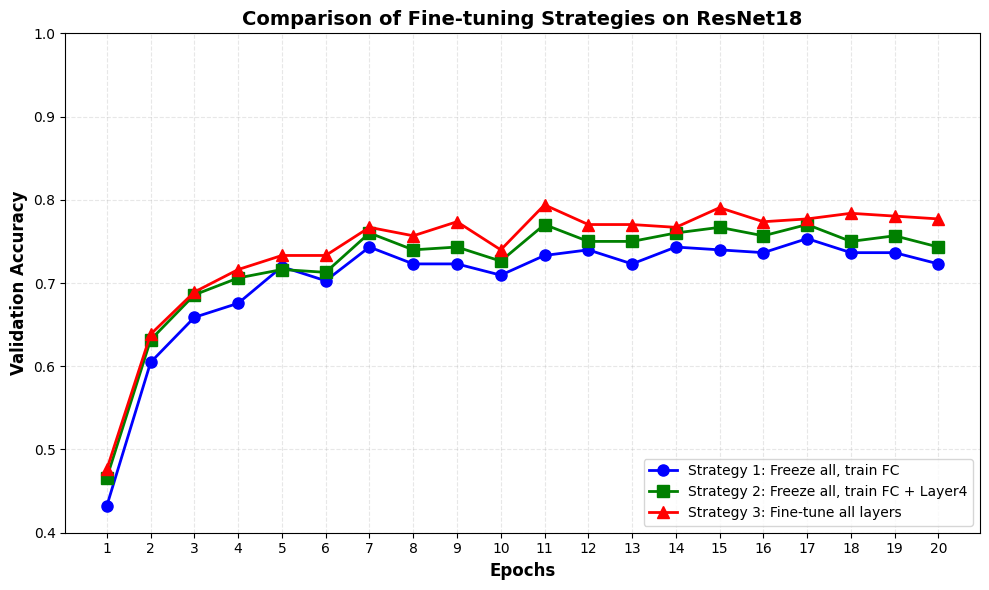

In [21]:
plot_metric(histories, 'valid_metrics', 'Validation Accuracy', True)

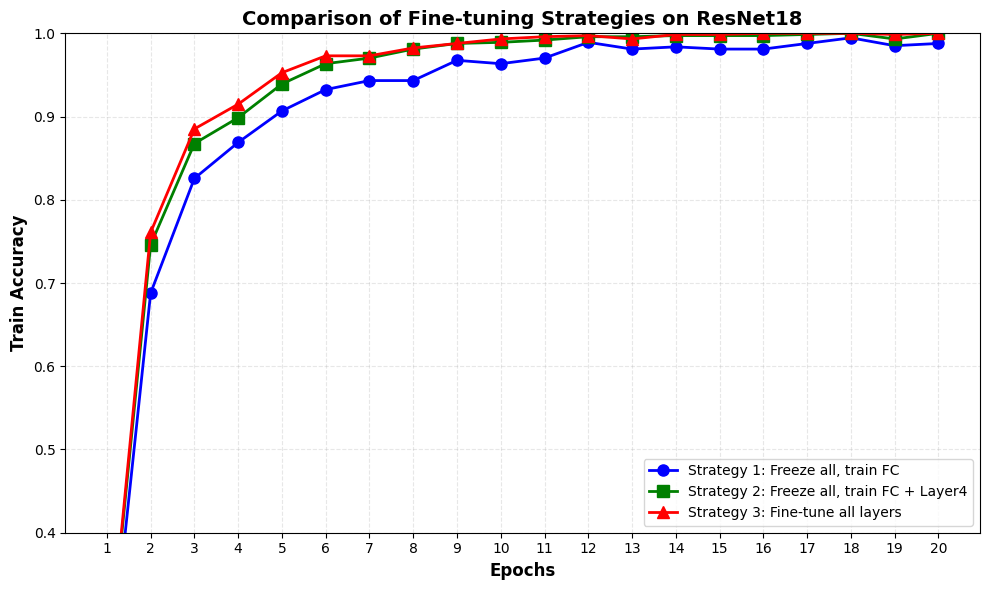

In [22]:
plot_metric(histories, 'train_metrics', 'Train Accuracy', False)

In [23]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        # TODO: register a forward hook on `target_layer` that stores its
        #       output into self.activations (detach it, but keep it on DEVICE)
        def forward_hook(module, input, output):
            self.activations = output.detach()
        self.forward_handle = target_layer.register_forward_hook(forward_hook)

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()
    
        # TODO: register a full backward hook on `target_layer` that stores
        #       the gradient with respect to its OUTPUT into self.gradients
        #       (grad_output is a tuple; you want grad_output[0], detached)
        self.backward_handle = target_layer.register_full_backward_hook(backward_hook)
        
    def __call__(self, input_tensor, class_index=None):
        '''Run one image (shape [1, 3, 224, 224]) through the model and
        return a single-channel heatmap of shape [H, W] (same H, W as the
        target layer's activation maps).'''
        self.model.eval()
        logits = self.model(input_tensor)

        if class_index is None:
            class_index = logits.argmax(dim=1).item()

        # TODO: zero any existing gradients, then backpropagate from
        #       logits[0, class_index] (a scalar) to populate self.gradients
        #       via the backward hook you registered above.
        self.model.zero_grad()
        class_score = logits[0, class_index]
        class_score.backward()

        # TODO: compute alpha_k = mean of self.gradients over spatial dims (H, W),
        #       for each channel k -- this is Equation "alpha" from Q3.1.
        #       self.gradients has shape [1, C, H, W]; alpha should end up [C].
        alpha_k = self.gradients.mean(dim=(2, 3))

        # TODO: compute the weighted sum over channels: sum_k(alpha_k * activations_k),
        #       giving a [H, W] map, then apply ReLU -- this is the second equation.
        sum_k = (alpha_k[:, :, None, None] * self.activations).sum(dim=1)
        cam = torch.relu(sum_k)
        # TODO: return the [H, W] heatmap as a numpy array, normalized to [0, 1]
        #       (subtract its min, divide by its max, guarding against divide-by-zero)
        cam = cam.squeeze(0).detach()
        
        cam_min = cam.min()
        cam_max = cam.max()
        
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = torch.zeros_like(cam)
        return cam

In [24]:
import torch.nn.functional as F

gradcam = GradCAM(feature_model, feature_model.layer4)

def overlay_heatmap(image_tensor, heatmap, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    # TODO: denormalize image_tensor (mean/std), permute to (H, W, C), clamp to [0, 1]
    mean = torch.tensor(mean, device=image_tensor.device).view(3, 1, 1)
    std = torch.tensor(std, device=image_tensor.device).view(3, 1, 1)
    d_image_tensor = image_tensor * std + mean
    d_image_tensor = d_image_tensor.permute(1, 2, 0)
    d_image_tensor = d_image_tensor.clamp(0, 1)
    # TODO: resize `heatmap` (currently [h, w], likely 7x7 for ResNet18's layer4)
    #       up to 224x224 using F.interpolate on a reshaped [1, 1, h, w] tensor
    r_heatmap = F.interpolate(heatmap[None, None, :, :], (224, 224),mode="bilinear", align_corners=False)
    # TODO: plot the denormalized image, then plt.imshow(resized_heatmap, cmap="jet", alpha=0.5) on top
    plt.imshow(d_image_tensor.cpu().numpy(), cmap='jet')
    plt.imshow(r_heatmap.squeeze().cpu().numpy(), cmap="jet", alpha=0.5)


# TODO: find 4 validation images the frozen `feature_model` predicts CORRECTLY,
#       run gradcam on each (using the predicted class), and show the overlay
#       in a 2x2 grid with the breed name as the title.
#
# IMPORTANT GOTCHA: feature_model's backbone is entirely frozen
# (requires_grad=False everywhere except fc). If every tensor feeding into
# layer4 has requires_grad=False, PyTorch builds no autograd graph through it
# at all -- your backward hook will simply never fire, and self.gradients will
# stay None. Fix: before calling gradcam(...), do
#   single_image = images[i:i+1].clone().requires_grad_(True)
# so there's something upstream of layer4 for autograd to track, even though
# none of the model's own parameters need gradients for this to work.

In [28]:
def predict(model, valid_loader):
    X_batch, y_batch = next(iter(valid_loader))
    X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
    logits = model(X_batch)
    probs = torch.softmax(logits, dim=0)
    y_pred = torch.argmax(probs, dim=1)
    correct_mask = y_pred == y_batch
    true_preds = X_batch[correct_mask]
    true_labels = y_batch[correct_mask]
    return true_preds, true_labels

model, optimizer = make_finetune_model("none")
state_dict = torch.load(
    "models/none_model_weights.pth",
    map_location=DEVICE,
    weights_only=True
)

true_preds, true_labels = predict(feature_model, valid_loader)

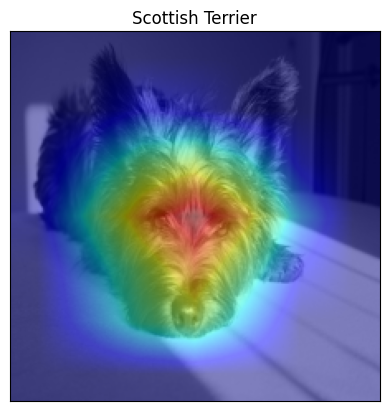

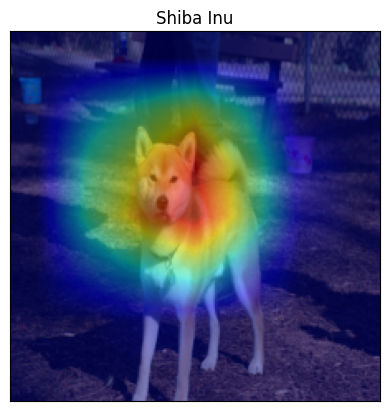

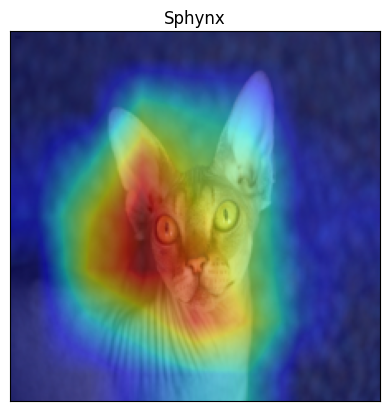

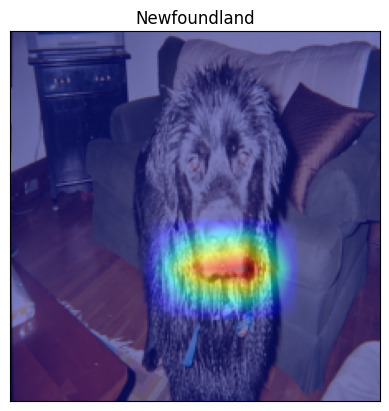

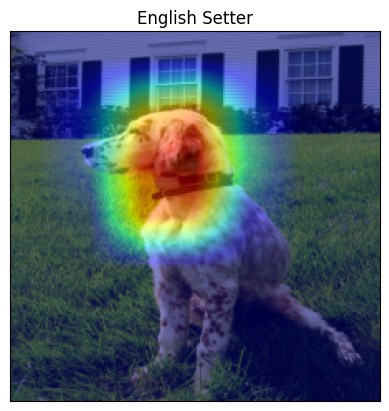

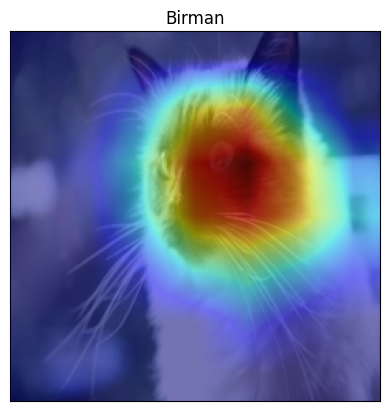

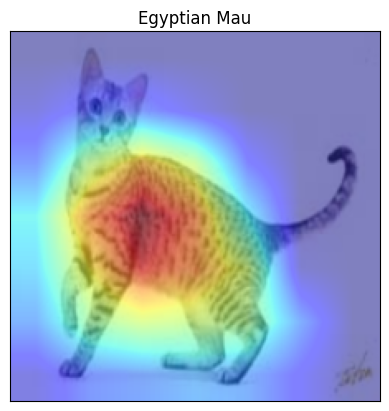

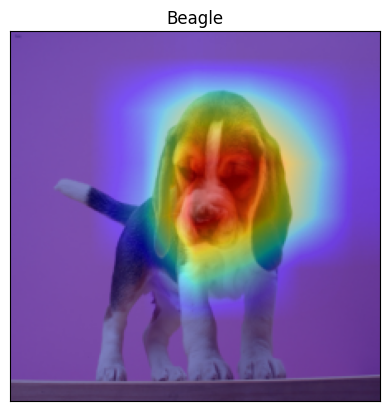

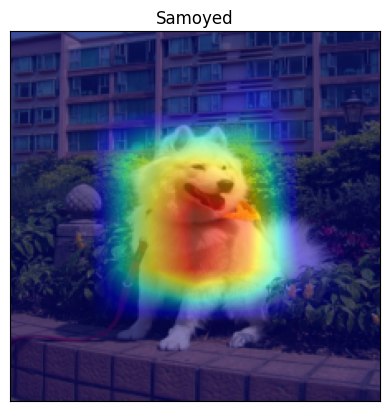

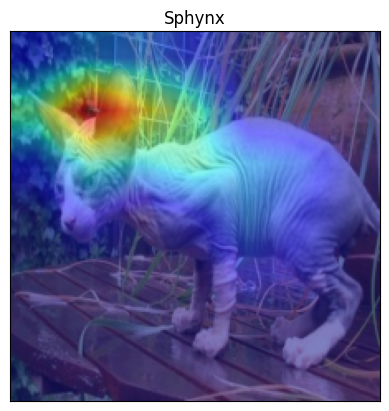

In [29]:
for i in range(10):
    plt.figure()
    plt.title(class_names[true_labels[i].cpu().item()])
    plt.xticks([])
    plt.yticks([])
    overlay_heatmap(true_preds[i], gradcam(true_preds[i:i+1].clone().requires_grad_(True)))

In [30]:
model, optimizer = make_finetune_model("all")

state_dict = torch.load(
    "models/all_model_weights.pth",
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(state_dict)
model.to(DEVICE)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [31]:
# true_preds_all, true_labels_all = predict(model, valid_loader)
gradcam2 = GradCAM(model, model.layer4)

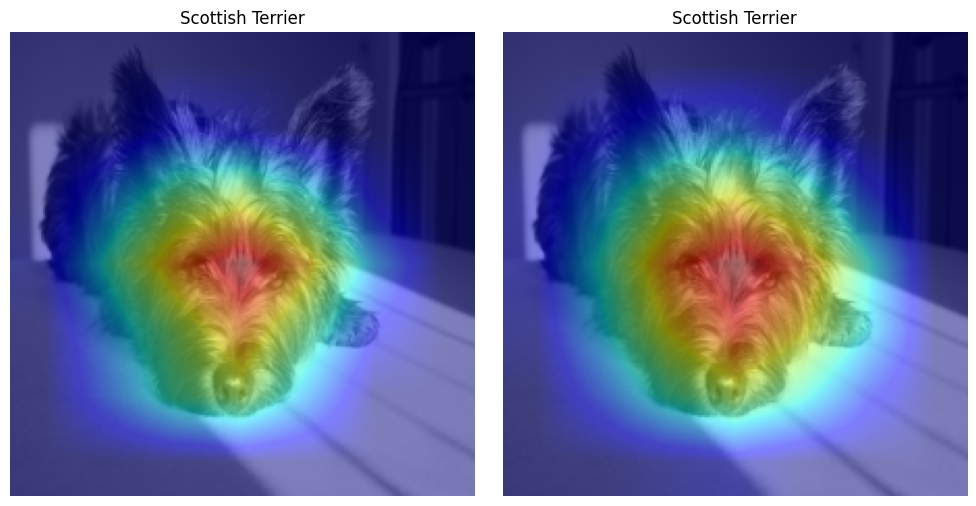

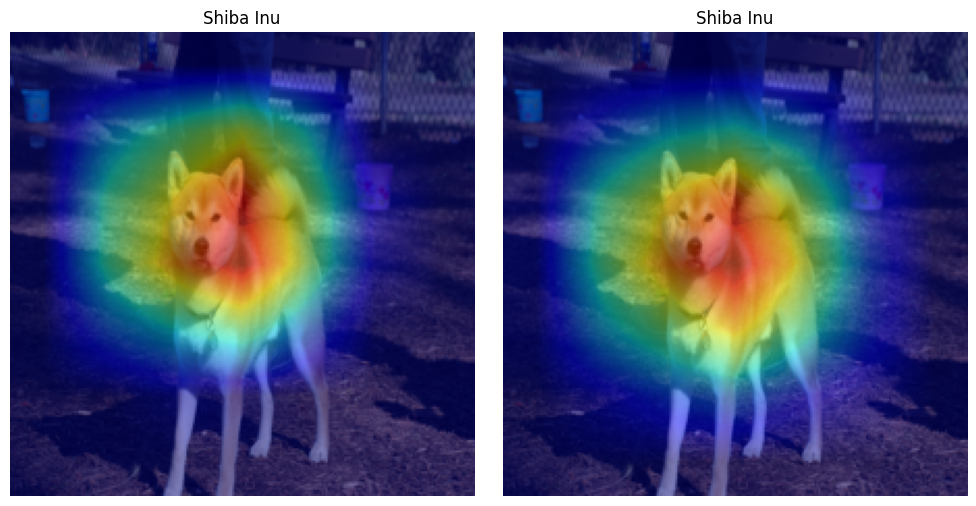

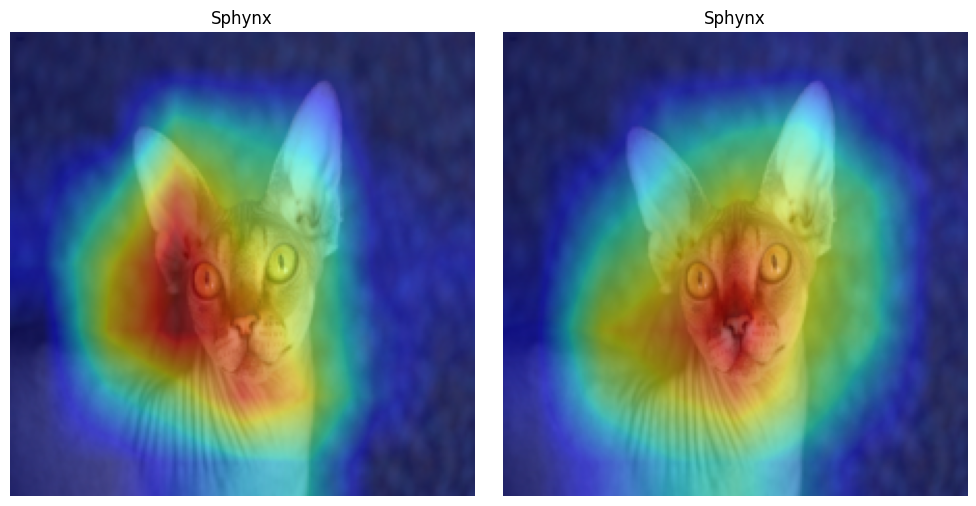

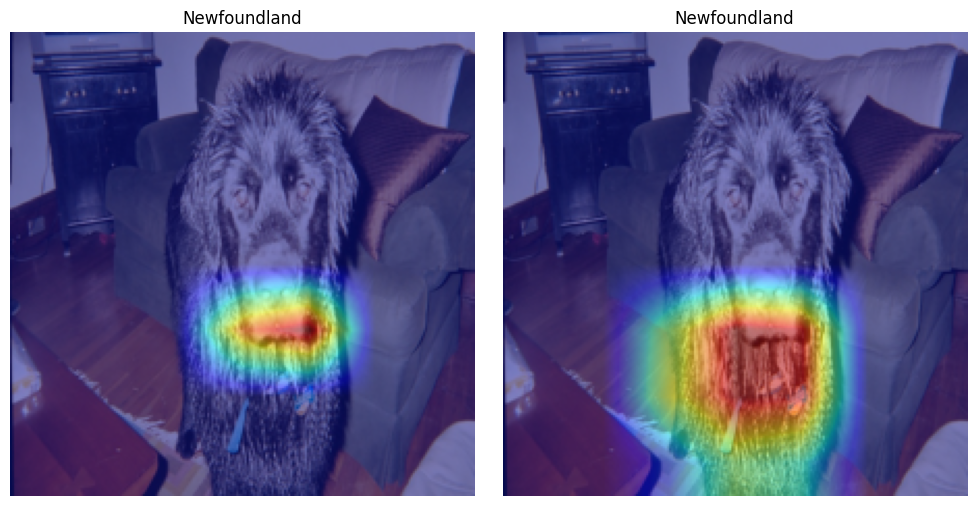

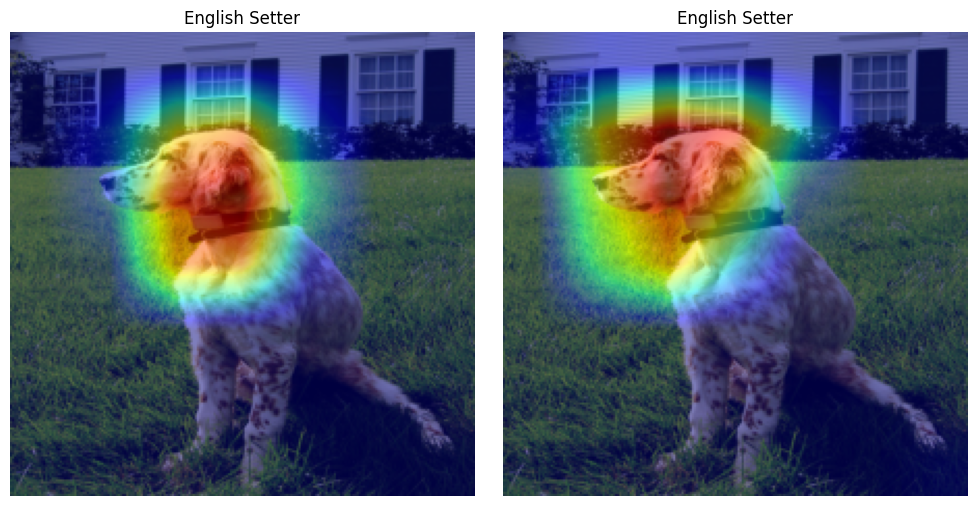

...

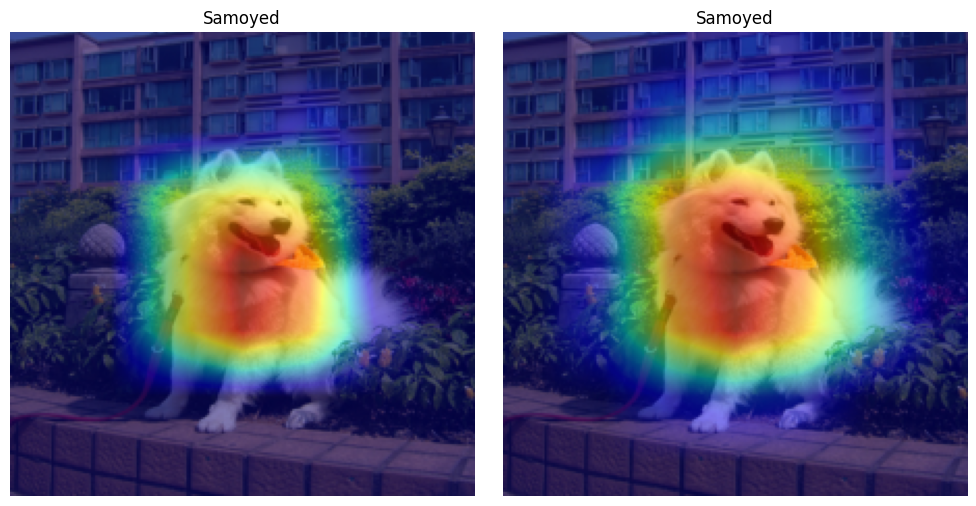

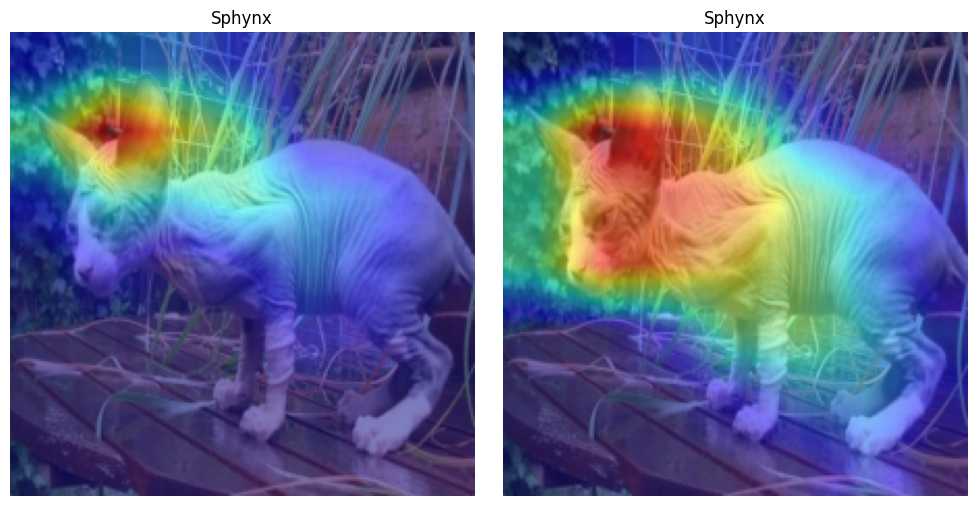

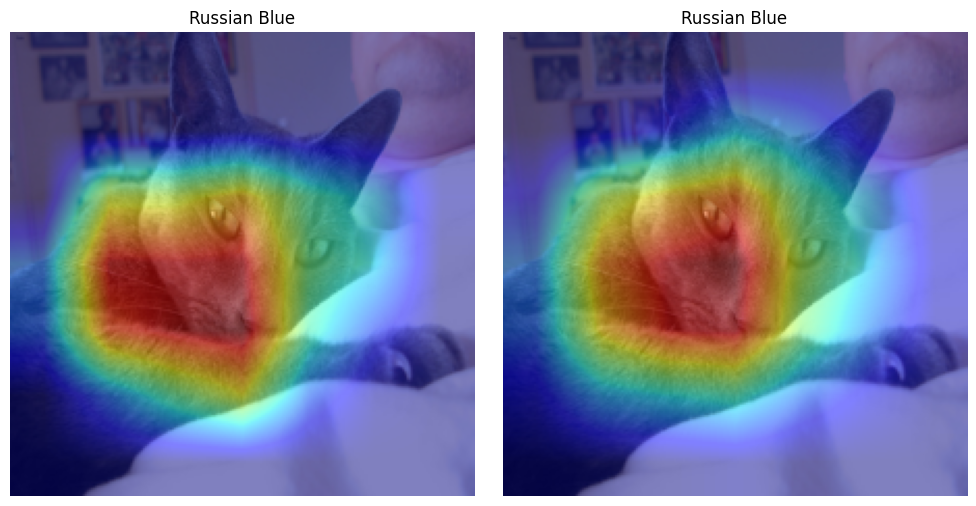

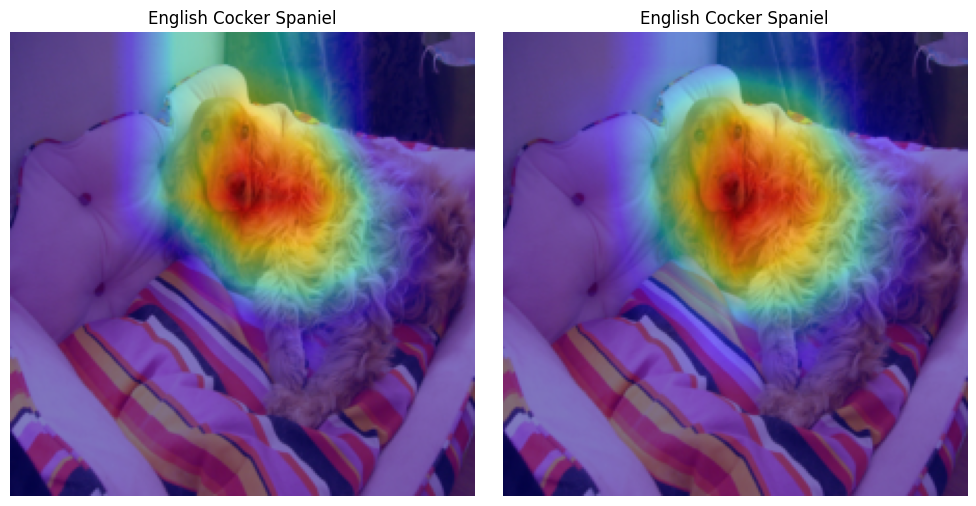

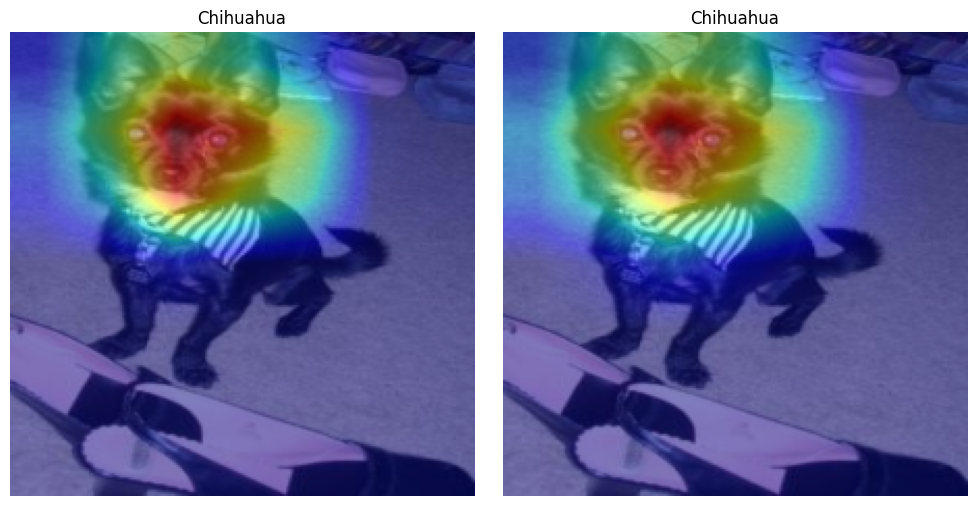

In [32]:
for i in range(13):
    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    overlay_heatmap(true_preds[i], gradcam(true_preds[i:i+1].clone().requires_grad_(True)))
    plt.title(class_names[true_labels[i].cpu().item()])
    plt.axis("off")
    
    plt.subplot(122)
    overlay_heatmap(true_preds[i], gradcam2(true_preds[i:i+1].clone().requires_grad_(True)))
    plt.title(class_names[true_labels[i].cpu().item()])
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [33]:
batch_size = 10
indices = torch.randperm(batch_size)
len(class_names)

37

In [34]:
def mixup_batch(images, labels, alpha=0.2, seed=None):
    '''Return (mixed_images, labels_a, labels_b, lam) using the
    same-batch-shuffle trick from Q4.3.'''
    if seed is not None:
        np.random.seed(seed)
        torch.manual_seed(seed)

    # TODO: sample a single lambda from np.random.beta(alpha, alpha)
    lambda_value = float(np.random.beta(alpha, alpha))
    # TODO: build a random permutation of the batch indices (torch.randperm)
    batch_size = images.shape[0]
    permutation = torch.randperm(batch_size, device=images.device)
    # TODO: mixed_images = lam * images + (1 - lam) * images[permutation]
    mixed_images = lambda_value * images + (1 - lambda_value) * images[permutation]
    # TODO: labels_a = labels (original order), labels_b = labels[permutation]
    labels_a = labels.clone()
    labels_b = labels[permutation].clone()
    # TODO: return mixed_images, labels_a, labels_b, lam
    return mixed_images, labels_a, labels_b, lambda_value, permutation


def mixup_loss(loss_fn, logits, labels_a, labels_b, lam):
    # TODO: return lam * loss_fn(logits, labels_a) + (1 - lam) * loss_fn(logits, labels_b)
    return lam * loss_fn(logits, labels_a) + (1 - lam) * loss_fn(logits, labels_b)

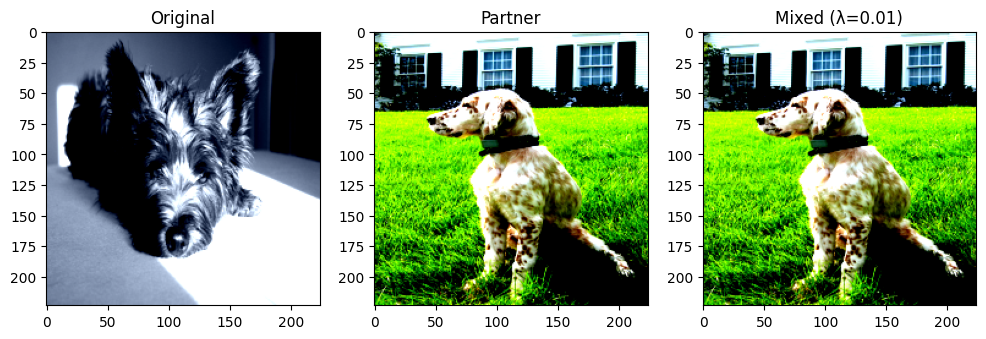

In [35]:
# TODO: grab one batch from train_loader
# train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(val_dataset, shuffle=False)
images, labels = next(iter(train_loader))
# TODO: call mixup_batch on it
mixed_images, labels_a, labels_b, lam, permutation = mixup_batch(images, labels, alpha=0.2, seed=SEED)
# TODO: pick index 0, find its permutation partner, and plot all three images
#       (original, partner, and mixed) side by side with lambda in the title

idx = 0
partner_idx = permutation[idx].item()

plt.figure(figsize=(12, 4))
d_image = images[idx] * 0.5 + 0.5
d_image = torch.clip(d_image, 0, 1)
plt.subplot(131)
plt.imshow(d_image.permute(1, 2, 0))
plt.title("Original")

plt.subplot(132)
d_partner_image = images[partner_idx] * 0.5 + 0.5
d_partner_image = torch.clip(d_partner_image, 0, 1)
plt.imshow(d_partner_image.permute(1, 2, 0))
plt.title("Partner")

plt.subplot(133)
d_mixed_image = mixed_images[idx] * 0.5 + 0.5
d_mixed_image = torch.clip(d_mixed_image, 0, 1)
plt.imshow(d_mixed_image.permute(1, 2, 0))
plt.title(f"Mixed (λ={lam:.2f})")

plt.show()

In [37]:
set_seed()

weights = ResNet18_Weights.DEFAULT

feature_model = resnet18(weights=weights)

freeze_layers(feature_model, layer_names=None, unfreeze=False)

num_features = feature_model.fc.in_features
feature_model.fc = nn.Linear(num_features, NUM_CLASSES)
feature_model = feature_model.to(DEVICE)
feature_model.trainable_modules = [feature_model.fc]

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)

optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)

print("Training ...\n\n")
n_epochs = 20
history1 = train(feature_model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="no_mixuap", frozen_bn_layers=["layer1", "layer2", "layer3", "layer4"], patience=2, factor=0.5, epoch_callback=None, device=DEVICE)

Training ...




Epoch 1/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:09<00:00,  4.75batch/s, loss=2.9560, metric=25.41%]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 2.9560, Train Metric: 25.41%, Valid Metric: 49.32%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.46batch/s, loss=1.2849, metric=78.65%]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 1.2849, Train Metric: 78.65%, Valid Metric: 66.22%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.63batch/s, loss=0.7647, metric=88.78%]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 0.7647, Train Metric: 88.78%, Valid Metric: 70.61%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.36batch/s, loss=0.5368, metric=93.11%]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 0.5368, Train Metric: 93.11%, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.44batch/s, loss=0.4091, metric=95.95%]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 0.4091, Train Metric: 95.95%, Valid Metric: 77.03%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.60batch/s, loss=0.3208, metric=96.22%]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 0.3208, Train Metric: 96.22%, Valid Metric: 75.00%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.68batch/s, loss=0.2588, metric=97.16%]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 0.2588, Train Metric: 97.16%, Valid Metric: 77.70%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=0.2168, metric=98.51%]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 0.2168, Train Metric: 98.51%, Valid Metric: 77.36%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|███████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=0.1924, metric=97.70%]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 0.1924, Train Metric: 97.70%, Valid Metric: 79.73%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=0.1745, metric=98.24%]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 0.1745, Train Metric: 98.24%, Valid Metric: 76.35%, LR: 1.00e-03



Epoch 11/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.25batch/s, loss=0.1581, metric=99.05%]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 0.1581, Train Metric: 99.05%, Valid Metric: 79.05%, LR: 1.00e-03



Epoch 12/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.48batch/s, loss=0.1331, metric=99.73%]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 0.1331, Train Metric: 99.73%, Valid Metric: 78.72%, LR: 5.00e-04



Epoch 13/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.19batch/s, loss=0.1183, metric=99.73%]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 0.1183, Train Metric: 99.73%, Valid Metric: 78.04%, LR: 5.00e-04



Epoch 14/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.25batch/s, loss=0.1071, metric=99.46%]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 0.1071, Train Metric: 99.46%, Valid Metric: 78.38%, LR: 5.00e-04



Epoch 15/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=0.0979, metric=99.86%]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 0.0979, Train Metric: 99.86%, Valid Metric: 78.38%, LR: 2.50e-04



Epoch 16/20 [Train]: 100%|█████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.25batch/s, loss=0.0940, metric=100.00%]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 0.0940, Train Metric: 100.00%, Valid Metric: 78.04%, LR: 2.50e-04



Epoch 17/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.23batch/s, loss=0.0951, metric=99.86%]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 0.0951, Train Metric: 99.86%, Valid Metric: 78.38%, LR: 2.50e-04



Epoch 18/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.13batch/s, loss=0.0877, metric=99.73%]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 0.0877, Train Metric: 99.73%, Valid Metric: 78.38%, LR: 1.25e-04



Epoch 19/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.40batch/s, loss=0.0900, metric=99.86%]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 0.0900, Train Metric: 99.86%, Valid Metric: 78.72%, LR: 1.25e-04



Epoch 20/20 [Train]: 100%|██████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.47batch/s, loss=0.0862, metric=99.73%]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 0.0862, Train Metric: 99.73%, Valid Metric: 78.72%, LR: 1.25e-04



In [39]:
def train2(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name, frozen_bn_layers=["layer1", "layer2", "layer3", "layer4"], patience=2, factor=0.5, epoch_callback=None, device='cuda', alpha=0.2):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "valid_metrics": []}
    best_valid_score = -1.
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()

        if frozen_bn_layers is not None:
            set_bn_eval(model, frozen_bn_layers)
        
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        
        # Create progress bar for this epoch
        train_pbar = tqdm(train_loader, 
                         desc=f"Epoch {epoch+1}/{n_epochs} [Train]",
                         leave=True,  # Keep the bar after completion
                         unit="batch",
                         dynamic_ncols=True)  # Adapt to terminal width
        
        for batch_idx, (X_batch, y_batch) in enumerate(train_pbar):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            mixed_images, labels_a, labels_b, lam, _ = mixup_batch(X_batch, y_batch, alpha)
            y_pred = model(mixed_images)
            loss = mixup_loss(loss_fn, y_pred, labels_a, labels_b, lam)
            total_loss += loss.item()
            
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
           
            # Update progress bar with current metrics (only once per batch)
            avg_loss = total_loss / (batch_idx + 1)
            train_pbar.set_postfix({
                'loss': f'{avg_loss:.4f}',
            })
        
        # Calculate epoch averages
        avg_train_loss = total_loss / len(train_loader)
        
        history["train_losses"].append(avg_train_loss)

        
        # Validation
        val_metric = evaluate_tm(model, valid_loader, metric, device=device)
        if val_metric > best_valid_score:
            best_valid_score = val_metric
            torch.save(model.state_dict(), f"models/{model_name}_model_weights.pth")
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        
        # Print epoch summary (clear line and print)
        print(f"\nEpoch {epoch+1}/{n_epochs} - "
              f"Train Loss: {avg_train_loss:.4f}, "
              f"Valid Metric: {val_metric:.2%}, "
              f"LR: {optimizer.param_groups[0]['lr']:.2e}\n")
    
    return history

In [40]:
set_seed()

weights = ResNet18_Weights.DEFAULT

feature_model = resnet18(weights=weights)
# freeze every parameter
freeze_layers(feature_model, layer_names=None, unfreeze=False)
# print("Trainable modules after freezing all layers")
# print_trainable_params(feature_model)
# TODO: replace feature_model.fc with a fresh nn.Linear(..., NUM_CLASSES)
num_features = feature_model.fc.in_features
feature_model.fc = nn.Linear(num_features, NUM_CLASSES)
feature_model = feature_model.to(DEVICE)
feature_model.trainable_modules = [feature_model.fc]
# print("Trainable modules after adding new fc to the model")
# print_trainable_params(feature_model)

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)

optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)

print("Training ...\n\n")
n_epochs = 20
history2 = train2(feature_model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="mixuap", patience=2, factor=0.5, epoch_callback=None, device=DEVICE)

Training ...




Epoch 1/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=3.1981]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 3.1981, Valid Metric: 47.30%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=1.7289]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 1.7289, Valid Metric: 61.82%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.4083]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 1.4083, Valid Metric: 67.57%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.55batch/s, loss=1.1322]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 1.1322, Valid Metric: 70.61%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.19batch/s, loss=0.9321]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 0.9321, Valid Metric: 75.00%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.57batch/s, loss=0.8267]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 0.8267, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.29batch/s, loss=0.8059]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 0.8059, Valid Metric: 77.36%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.37batch/s, loss=0.9193]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 0.9193, Valid Metric: 75.68%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.32batch/s, loss=0.8048]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 0.8048, Valid Metric: 79.73%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=0.7931]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 0.7931, Valid Metric: 75.68%, LR: 1.00e-03



Epoch 11/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=0.7564]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 0.7564, Valid Metric: 78.04%, LR: 1.00e-03



Epoch 12/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.15batch/s, loss=0.8029]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 0.8029, Valid Metric: 79.39%, LR: 5.00e-04



Epoch 13/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.15batch/s, loss=0.7471]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 0.7471, Valid Metric: 77.36%, LR: 5.00e-04



Epoch 14/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.37batch/s, loss=0.7956]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 0.7956, Valid Metric: 76.69%, LR: 5.00e-04



Epoch 15/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=0.7931]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 0.7931, Valid Metric: 76.35%, LR: 2.50e-04



Epoch 16/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=0.8966]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 0.8966, Valid Metric: 79.73%, LR: 2.50e-04



Epoch 17/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.18batch/s, loss=0.7141]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 0.7141, Valid Metric: 78.38%, LR: 2.50e-04



Epoch 18/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=0.6516]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 0.6516, Valid Metric: 77.03%, LR: 1.25e-04



Epoch 19/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.29batch/s, loss=0.8486]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 0.8486, Valid Metric: 78.04%, LR: 1.25e-04



Epoch 20/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.41batch/s, loss=0.7351]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 0.7351, Valid Metric: 77.70%, LR: 1.25e-04



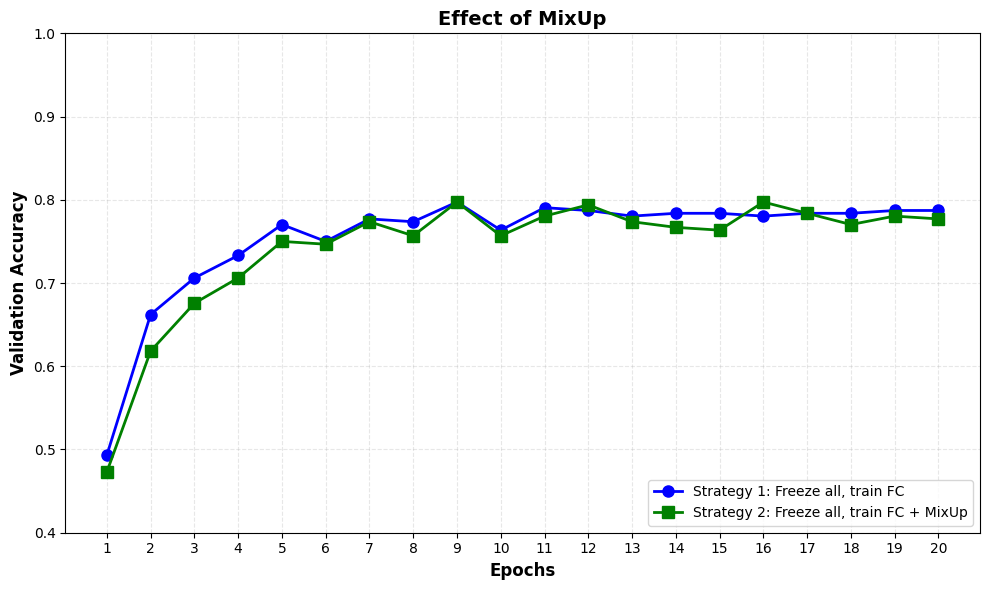

In [41]:
histories = [history1, history2]

plt.figure(figsize=(10, 6))
epochs = range(1, n_epochs + 1)
val_acc_strategy1 = [val.item() for val in histories[0]['valid_metrics']]
val_acc_strategy2 = [val.item() for val in histories[1]['valid_metrics']]

plt.plot(epochs, val_acc_strategy1, 
         marker='o', linewidth=2, markersize=8, 
         label='Strategy 1: Freeze all, train FC', color='blue')

plt.plot(epochs, val_acc_strategy2, 
         marker='s', linewidth=2, markersize=8, 
         label='Strategy 2: Freeze all, train FC + MixUp', color='green')

# Customize the plot
plt.xlabel('Epochs', fontsize=12, fontweight='bold')
plt.ylabel('Validation Accuracy', fontsize=12, fontweight='bold')
plt.title('Effect of MixUp', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3, linestyle='--')
plt.ylim([0.4, 1.0])  # Set y-axis limits
plt.xticks(epochs)  # Show all epoch numbers
plt.tight_layout()
plt.show()

In [43]:
set_seed()

weights = ResNet18_Weights.DEFAULT

feature_model = resnet18(weights=weights)
# freeze every parameter
freeze_layers(feature_model, layer_names=None, unfreeze=False)
# print("Trainable modules after freezing all layers")
# print_trainable_params(feature_model)
# TODO: replace feature_model.fc with a fresh nn.Linear(..., NUM_CLASSES)
num_features = feature_model.fc.in_features
feature_model.fc = nn.Linear(num_features, NUM_CLASSES)
feature_model = feature_model.to(DEVICE)
feature_model.trainable_modules = [feature_model.fc]
# print("Trainable modules after adding new fc to the model")
# print_trainable_params(feature_model)

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)

optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)

print("Training ...\n\n")
n_epochs = 20
history2 = train2(feature_model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="mixap-alpha-05", patience=2, factor=0.5, epoch_callback=None, device=DEVICE, alpha=0.5)

Training ...




Epoch 1/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.61batch/s, loss=3.3752]
                                                                                                                                                           


Epoch 1/20 - Train Loss: 3.3752, Valid Metric: 40.88%, LR: 1.00e-03



Epoch 2/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.49batch/s, loss=2.1194]
                                                                                                                                                           


Epoch 2/20 - Train Loss: 2.1194, Valid Metric: 58.45%, LR: 1.00e-03



Epoch 3/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=1.7019]
                                                                                                                                                           


Epoch 3/20 - Train Loss: 1.7019, Valid Metric: 66.55%, LR: 1.00e-03



Epoch 4/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=1.3243]
                                                                                                                                                           


Epoch 4/20 - Train Loss: 1.3243, Valid Metric: 66.55%, LR: 1.00e-03



Epoch 5/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.34batch/s, loss=1.6067]
                                                                                                                                                           


Epoch 5/20 - Train Loss: 1.6067, Valid Metric: 69.26%, LR: 1.00e-03



Epoch 6/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.29batch/s, loss=1.4736]
                                                                                                                                                           


Epoch 6/20 - Train Loss: 1.4736, Valid Metric: 70.95%, LR: 1.00e-03



Epoch 7/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.50batch/s, loss=1.3242]
                                                                                                                                                           


Epoch 7/20 - Train Loss: 1.3242, Valid Metric: 75.68%, LR: 1.00e-03



Epoch 8/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=1.2534]
                                                                                                                                                           


Epoch 8/20 - Train Loss: 1.2534, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 9/20 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=1.1609]
                                                                                                                                                           


Epoch 9/20 - Train Loss: 1.1609, Valid Metric: 77.70%, LR: 1.00e-03



Epoch 10/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.26batch/s, loss=1.3047]
                                                                                                                                                           


Epoch 10/20 - Train Loss: 1.3047, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 11/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.26batch/s, loss=1.2090]
                                                                                                                                                           


Epoch 11/20 - Train Loss: 1.2090, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 12/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.20batch/s, loss=1.3810]
                                                                                                                                                           


Epoch 12/20 - Train Loss: 1.3810, Valid Metric: 72.64%, LR: 5.00e-04



Epoch 13/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.22batch/s, loss=1.2573]
                                                                                                                                                           


Epoch 13/20 - Train Loss: 1.2573, Valid Metric: 74.32%, LR: 5.00e-04



Epoch 14/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.11batch/s, loss=1.1883]
                                                                                                                                                           


Epoch 14/20 - Train Loss: 1.1883, Valid Metric: 74.66%, LR: 5.00e-04



Epoch 15/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=1.0693]
                                                                                                                                                           


Epoch 15/20 - Train Loss: 1.0693, Valid Metric: 75.68%, LR: 2.50e-04



Epoch 16/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.32batch/s, loss=1.1844]
                                                                                                                                                           


Epoch 16/20 - Train Loss: 1.1844, Valid Metric: 76.35%, LR: 2.50e-04



Epoch 17/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.2010]
                                                                                                                                                           


Epoch 17/20 - Train Loss: 1.2010, Valid Metric: 75.00%, LR: 2.50e-04



Epoch 18/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.50batch/s, loss=1.1451]
                                                                                                                                                           


Epoch 18/20 - Train Loss: 1.1451, Valid Metric: 75.68%, LR: 1.25e-04



Epoch 19/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.27batch/s, loss=1.0511]
                                                                                                                                                           


Epoch 19/20 - Train Loss: 1.0511, Valid Metric: 76.35%, LR: 1.25e-04



Epoch 20/20 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.41batch/s, loss=1.1438]
                                                                                                                                                           


Epoch 20/20 - Train Loss: 1.1438, Valid Metric: 76.01%, LR: 1.25e-04



In [44]:
set_seed()

weights = ResNet18_Weights.DEFAULT

feature_model = resnet18(weights=weights)
# freeze every parameter
freeze_layers(feature_model, layer_names=None, unfreeze=False)
# print("Trainable modules after freezing all layers")
# print_trainable_params(feature_model)
# TODO: replace feature_model.fc with a fresh nn.Linear(..., NUM_CLASSES)
num_features = feature_model.fc.in_features
feature_model.fc = nn.Linear(num_features, NUM_CLASSES)
feature_model = feature_model.to(DEVICE)
feature_model.trainable_modules = [feature_model.fc]
# print("Trainable modules after adding new fc to the model")
# print_trainable_params(feature_model)

train_dataset_aug = TransformSubset(raw_trainval, train_indices, train_transform)
train_loader = make_loader(train_dataset_aug, shuffle=True)
valid_loader = make_loader(val_dataset, shuffle=False)

optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass",
                                 num_classes=NUM_CLASSES).to(DEVICE)

print("Training ...\n\n")
n_epochs = 50
history2 = train2(feature_model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, model_name="more_patience", patience=5, factor=0.5, epoch_callback=None, device=DEVICE, alpha=0.5)

Training ...




Epoch 1/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.35batch/s, loss=3.3752]
                                                                                                                                                           


Epoch 1/50 - Train Loss: 3.3752, Valid Metric: 40.88%, LR: 1.00e-03



Epoch 2/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=2.1194]
                                                                                                                                                           


Epoch 2/50 - Train Loss: 2.1194, Valid Metric: 58.45%, LR: 1.00e-03



Epoch 3/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.41batch/s, loss=1.7019]
                                                                                                                                                           


Epoch 3/50 - Train Loss: 1.7019, Valid Metric: 66.55%, LR: 1.00e-03



Epoch 4/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=1.3243]
                                                                                                                                                           


Epoch 4/50 - Train Loss: 1.3243, Valid Metric: 66.55%, LR: 1.00e-03



Epoch 5/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.25batch/s, loss=1.6067]
                                                                                                                                                           


Epoch 5/50 - Train Loss: 1.6067, Valid Metric: 69.26%, LR: 1.00e-03



Epoch 6/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.45batch/s, loss=1.4736]
                                                                                                                                                           


Epoch 6/50 - Train Loss: 1.4736, Valid Metric: 70.95%, LR: 1.00e-03



Epoch 7/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.46batch/s, loss=1.3242]
                                                                                                                                                           


Epoch 7/50 - Train Loss: 1.3242, Valid Metric: 75.68%, LR: 1.00e-03



Epoch 8/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.2534]
                                                                                                                                                           


Epoch 8/50 - Train Loss: 1.2534, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 9/50 [Train]: 100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.44batch/s, loss=1.1609]
                                                                                                                                                           


Epoch 9/50 - Train Loss: 1.1609, Valid Metric: 77.70%, LR: 1.00e-03



Epoch 10/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.45batch/s, loss=1.3047]
                                                                                                                                                           


Epoch 10/50 - Train Loss: 1.3047, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 11/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.28batch/s, loss=1.2090]
                                                                                                                                                           


Epoch 11/50 - Train Loss: 1.2090, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 12/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.17batch/s, loss=1.3810]
                                                                                                                                                           


Epoch 12/50 - Train Loss: 1.3810, Valid Metric: 72.64%, LR: 1.00e-03



Epoch 13/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.40batch/s, loss=1.2802]
                                                                                                                                                           


Epoch 13/50 - Train Loss: 1.2802, Valid Metric: 73.31%, LR: 1.00e-03



Epoch 14/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.13batch/s, loss=1.2175]
                                                                                                                                                           


Epoch 14/50 - Train Loss: 1.2175, Valid Metric: 74.66%, LR: 1.00e-03



Epoch 15/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.30batch/s, loss=1.0899]
                                                                                                                                                           


Epoch 15/50 - Train Loss: 1.0899, Valid Metric: 75.68%, LR: 5.00e-04



Epoch 16/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.54batch/s, loss=1.1837]
                                                                                                                                                           


Epoch 16/50 - Train Loss: 1.1837, Valid Metric: 76.01%, LR: 5.00e-04



Epoch 17/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.37batch/s, loss=1.2078]
                                                                                                                                                           


Epoch 17/50 - Train Loss: 1.2078, Valid Metric: 75.68%, LR: 5.00e-04



Epoch 18/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=1.1492]
                                                                                                                                                           


Epoch 18/50 - Train Loss: 1.1492, Valid Metric: 72.64%, LR: 5.00e-04



Epoch 19/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.04batch/s, loss=1.0481]
                                                                                                                                                           


Epoch 19/50 - Train Loss: 1.0481, Valid Metric: 73.65%, LR: 5.00e-04



Epoch 20/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.32batch/s, loss=1.1434]
                                                                                                                                                           


Epoch 20/50 - Train Loss: 1.1434, Valid Metric: 74.32%, LR: 5.00e-04



Epoch 21/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.32batch/s, loss=1.1936]
                                                                                                                                                           


Epoch 21/50 - Train Loss: 1.1936, Valid Metric: 71.96%, LR: 2.50e-04



Epoch 22/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=0.9989]
                                                                                                                                                           


Epoch 22/50 - Train Loss: 0.9989, Valid Metric: 76.01%, LR: 2.50e-04



Epoch 23/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.0861]
                                                                                                                                                           


Epoch 23/50 - Train Loss: 1.0861, Valid Metric: 77.36%, LR: 2.50e-04



Epoch 24/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.42batch/s, loss=0.9668]
                                                                                                                                                           


Epoch 24/50 - Train Loss: 0.9668, Valid Metric: 77.70%, LR: 2.50e-04



Epoch 25/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.53batch/s, loss=1.0511]
                                                                                                                                                           


Epoch 25/50 - Train Loss: 1.0511, Valid Metric: 74.32%, LR: 2.50e-04



Epoch 26/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=1.0263]
                                                                                                                                                           


Epoch 26/50 - Train Loss: 1.0263, Valid Metric: 77.03%, LR: 2.50e-04



Epoch 27/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.51batch/s, loss=1.1329]
                                                                                                                                                           


Epoch 27/50 - Train Loss: 1.1329, Valid Metric: 75.68%, LR: 1.25e-04



Epoch 28/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=1.1152]
                                                                                                                                                           


Epoch 28/50 - Train Loss: 1.1152, Valid Metric: 76.01%, LR: 1.25e-04



Epoch 29/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=1.1969]
                                                                                                                                                           


Epoch 29/50 - Train Loss: 1.1969, Valid Metric: 76.01%, LR: 1.25e-04



Epoch 30/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=0.9761]
                                                                                                                                                           


Epoch 30/50 - Train Loss: 0.9761, Valid Metric: 76.35%, LR: 1.25e-04



Epoch 31/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.36batch/s, loss=1.1259]
                                                                                                                                                           


Epoch 31/50 - Train Loss: 1.1259, Valid Metric: 77.03%, LR: 1.25e-04



Epoch 32/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.29batch/s, loss=1.1060]
                                                                                                                                                           


Epoch 32/50 - Train Loss: 1.1060, Valid Metric: 77.03%, LR: 1.25e-04



Epoch 33/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.1710]
                                                                                                                                                           


Epoch 33/50 - Train Loss: 1.1710, Valid Metric: 75.00%, LR: 6.25e-05



Epoch 34/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.18batch/s, loss=1.0279]
                                                                                                                                                           


Epoch 34/50 - Train Loss: 1.0279, Valid Metric: 76.69%, LR: 6.25e-05



Epoch 35/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.34batch/s, loss=1.0949]
                                                                                                                                                           


Epoch 35/50 - Train Loss: 1.0949, Valid Metric: 77.03%, LR: 6.25e-05



Epoch 36/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.16batch/s, loss=1.1689]
                                                                                                                                                           


Epoch 36/50 - Train Loss: 1.1689, Valid Metric: 76.01%, LR: 6.25e-05



Epoch 37/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.38batch/s, loss=1.1019]
                                                                                                                                                           


Epoch 37/50 - Train Loss: 1.1019, Valid Metric: 76.01%, LR: 6.25e-05



Epoch 38/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.00batch/s, loss=1.2279]
                                                                                                                                                           


Epoch 38/50 - Train Loss: 1.2279, Valid Metric: 77.03%, LR: 6.25e-05



Epoch 39/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.80batch/s, loss=1.1389]
                                                                                                                                                           


Epoch 39/50 - Train Loss: 1.1389, Valid Metric: 76.35%, LR: 3.13e-05



Epoch 40/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.87batch/s, loss=1.1221]
                                                                                                                                                           


Epoch 40/50 - Train Loss: 1.1221, Valid Metric: 76.35%, LR: 3.13e-05



Epoch 41/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:12<00:00,  3.85batch/s, loss=0.9003]
                                                                                                                                                           


Epoch 41/50 - Train Loss: 0.9003, Valid Metric: 76.69%, LR: 3.13e-05



Epoch 42/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.02batch/s, loss=1.0836]
                                                                                                                                                           


Epoch 42/50 - Train Loss: 1.0836, Valid Metric: 77.36%, LR: 3.13e-05



Epoch 43/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:11<00:00,  4.18batch/s, loss=1.1731]
                                                                                                                                                           


Epoch 43/50 - Train Loss: 1.1731, Valid Metric: 77.03%, LR: 3.13e-05



Epoch 44/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.51batch/s, loss=1.0731]
                                                                                                                                                           


Epoch 44/50 - Train Loss: 1.0731, Valid Metric: 76.69%, LR: 3.13e-05



Epoch 45/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.40batch/s, loss=1.1704]
                                                                                                                                                           


Epoch 45/50 - Train Loss: 1.1704, Valid Metric: 76.35%, LR: 1.56e-05



Epoch 46/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.33batch/s, loss=1.1352]
                                                                                                                                                           


Epoch 46/50 - Train Loss: 1.1352, Valid Metric: 76.69%, LR: 1.56e-05



Epoch 47/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.37batch/s, loss=1.0373]
                                                                                                                                                           


Epoch 47/50 - Train Loss: 1.0373, Valid Metric: 76.01%, LR: 1.56e-05



Epoch 48/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.31batch/s, loss=1.0513]
                                                                                                                                                           


Epoch 48/50 - Train Loss: 1.0513, Valid Metric: 76.69%, LR: 1.56e-05



Epoch 49/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.39batch/s, loss=0.9825]
                                                                                                                                                           


Epoch 49/50 - Train Loss: 0.9825, Valid Metric: 77.03%, LR: 1.56e-05



Epoch 50/50 [Train]: 100%|█████████████████████████████████████████████████████████████████████████████████| 47/47 [00:10<00:00,  4.43batch/s, loss=1.1887]
                                                                                                                                                           


Epoch 50/50 - Train Loss: 1.1887, Valid Metric: 76.35%, LR: 1.56e-05

